# IND320 Project Work Part 2

This notebook continues the same project from Part 1. I now read the reservoir data directly from NVE and prepare cross-border power transfer data through Cassandra, Spark and MongoDB.

GitHub repository: https://github.com/Sivan00/IND320-Sivan00-Project1/tree/project-part-2  
Streamlit app: https://ind320-sivan00-project1.streamlit.app/

## Setting up the notebook

I keep the imports together here so it is easier to see which packages are used in the local workflow.

In [1]:
import os
import tomllib
from pathlib import Path
from dotenv import load_dotenv

# The private settings load here without printing passwords or API keys.
# Existing environment variables take priority over my local file.
load_dotenv(Path(".env"), override=False)

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import requests

from data_utils import COLUMN_NAMES, MEASUREMENTS

# I reuse the app's local settings so I only need to keep one MongoDB password up to date.
# An environment variable still takes priority when running on another computer.
secrets_path = Path(".streamlit/secrets.toml")
if not os.environ.get("MONGODB_URI") and secrets_path.exists():
    with secrets_path.open("rb") as settings_file:
        settings = tomllib.load(settings_file)
    os.environ["MONGODB_URI"] = settings["mongo"]["uri"]

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#2F6F73", "#A45A52", "#947340", "#5D6699", "#77915F"]

2026-10-08 12:22:13.676 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-08 12:22:13.676 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


## Reading the reservoir data from NVE

The CSV from Part 1 is no longer used. This request goes to NVE's public Magasinstatistikk endpoint, and the original Norwegian headers are renamed in memory.

In [2]:
NVE_URL = (
    "https://biapi.nve.no/magasinstatistikk/api/"
    "Magasinstatistikk/HentOffentligData"
)

# A timeout prevents the notebook from waiting forever if the API is unavailable.
response = requests.get(NVE_URL, timeout=30)
response.raise_for_status()

reservoirs = pd.DataFrame(response.json()).rename(columns=COLUMN_NAMES)
reservoirs["date"] = pd.to_datetime(reservoirs["date"])
reservoirs = reservoirs.sort_values(
    ["date", "area_type", "area_number"]
).reset_index(drop=True)

print(f"Rows: {len(reservoirs):,}")
print(f"Period: {reservoirs['date'].min():%Y-%m-%d} to {reservoirs['date'].max():%Y-%m-%d}")
reservoirs.head()

Rows: 14,913
Period: 1995-01-08 to 2026-10-04


,date,area_type,area_number,iso_year,iso_week,fill_fraction,capacity_twh,stored_energy_twh,next_publication_date,previous_week_fill_fraction,weekly_change_fill_fraction
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
1,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657
2,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349
3,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,0001-01-01T00:00:00,0.801348,-0.242484
4,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160


## Understanding the NVE areas and download interval

I checked the area definitions in NVE's HentOmråder endpoint. EL means electricity bidding zones: EL 1 is NO1 (south-east), EL 2 is NO2 (south-west), EL 3 is NO3 (central), EL 4 is NO4 (north), and EL 5 is NO5 (west). The API type NO with number 0 means the whole country, so it should not be confused with the bidding-zone names NO1 to NO5.

VASS means watercourse regions. NVE describes VASS 1 as Østlandet, Agder and parts of Rogaland; VASS 2 as the rest of Rogaland and Vestland; VASS 3 as Møre og Romsdal, Trøndelag and southern Nordland; and VASS 4 as the rest of Nordland and further north. These boundaries differ from the electricity zones. At this check, the metadata listed VASS 4 but the measurement response only contained VASS 1 to 3. I report that gap instead of adding an empty region to the chart.

The documented HentOffentligData request has no date parameters. Following the updated assignment from 12 October, the Streamlit table and plot pages use a selection slider for the download interval. NVE first returns the full public history, and the app retains only the selected months locally. The same area radio buttons control both the main lines and the row-wise LineChartColumn graphics.

Sources: [NVE API and area definitions](https://biapi.nve.no/magasinstatistikk/swagger/index.html) and [NVE's explanation of the reservoir statistics](https://www.nve.no/energi/analyser-og-statistikk/om-magasinstatistikken/).

In [3]:
from data_utils import load_reservoir_areas

# I compare the area catalogue with the rows actually returned by NVE.
# A missing measurement series is different from a reservoir with zero water.
area_catalogue = load_reservoir_areas()
area_counts = reservoirs.groupby(["area_type", "area_number"]).size().rename("Rows returned")
area_check = area_catalogue.merge(
    area_counts.reset_index(), on=["area_type", "area_number"], how="left",
)
area_check["Rows returned"] = area_check["Rows returned"].fillna(0).astype(int)
display(area_check[["area_type", "area_number", "Area", "Coverage", "Rows returned"]])

2026-10-08 12:22:14.951 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-08 12:22:14.952 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,area_type,area_number,Area,Coverage,Rows returned
0,EL,1,NO1: South-eastern Norway,"Eastern Østlandet from Buskerud northwards, ex...",1657
1,EL,2,NO2: South-western Norway,"Most of Vestfold, Telemark, Agder and Rogaland...",1657
2,EL,3,NO3: Central Norway,"Northern and western Vestland, Innlandet west ...",1657
3,EL,4,NO4: Northern Norway,The rest of Trøndelag and Northern Norway.,1657
4,EL,5,NO5: Western Norway,"Central Vestland up to Sognefjorden, Indre Sog...",1657
5,NO,0,Norway,The whole country.,1657
6,VASS,1,South-eastern Norway,"Østlandet, Agder and parts of Rogaland.",1657
7,VASS,2,Western Norway,The rest of Rogaland and Vestland.,1657
8,VASS,3,Central Norway,"Møre og Romsdal, Trøndelag and southern Nordland.",1657
9,VASS,4,Northern Norway,The rest of Nordland and the areas further north.,0


## Recreating the reservoir plots

The national NO/0 series gives one observation per week. This avoids connecting several area systems in the same line and keeps the plots comparable with Part 1.

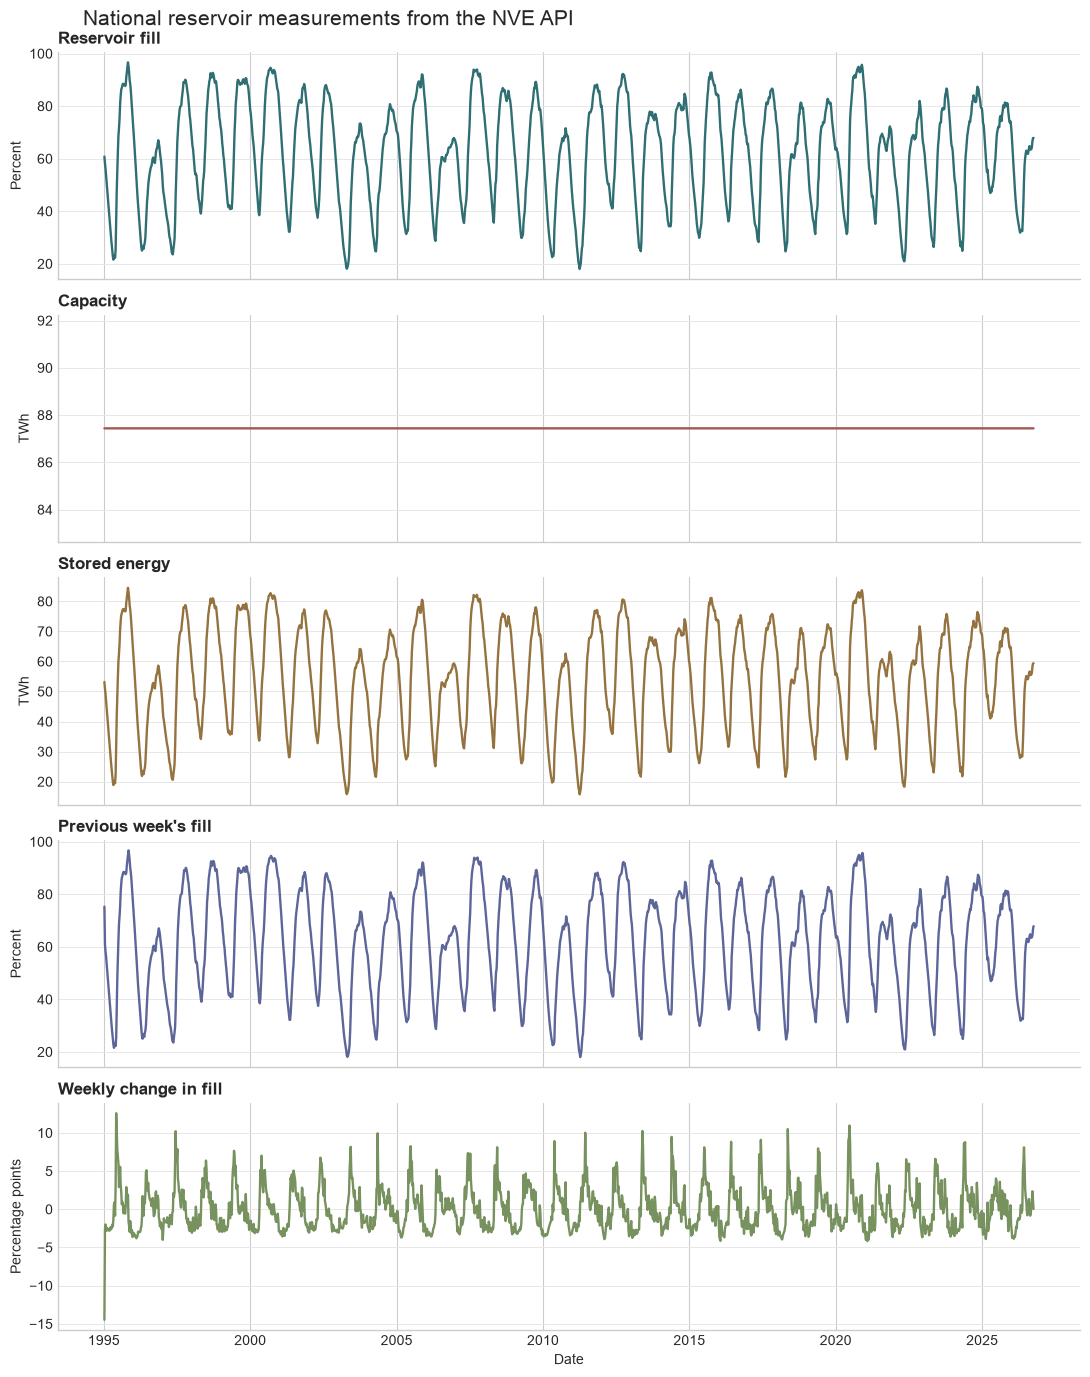

In [4]:
# NO/0 is the national total used for the time plots.
national = reservoirs.loc[
    (reservoirs["area_type"] == "NO") & (reservoirs["area_number"] == 0)
].copy()

fig, axes = plt.subplots(len(MEASUREMENTS), 1, figsize=(11, 14), sharex=True)

for ax, ((column, (title, unit, multiplier)), color) in zip(
    axes, zip(MEASUREMENTS.items(), COLORS)
):
    ax.plot(national["date"], national[column] * multiplier, color=color, linewidth=1.7)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_ylabel(unit)
    ax.grid(axis="y", color="#E7E7E7", linewidth=0.7)
    ax.spines[["top", "right"]].set_visible(False)

axes[-1].set_xlabel("Date")
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=9))
axes[-1].xaxis.set_major_formatter(
    mdates.ConciseDateFormatter(axes[-1].xaxis.get_major_locator())
)
fig.suptitle("National reservoir measurements from the NVE API", x=0.08, ha="left", fontsize=15)
fig.tight_layout()
plt.show()

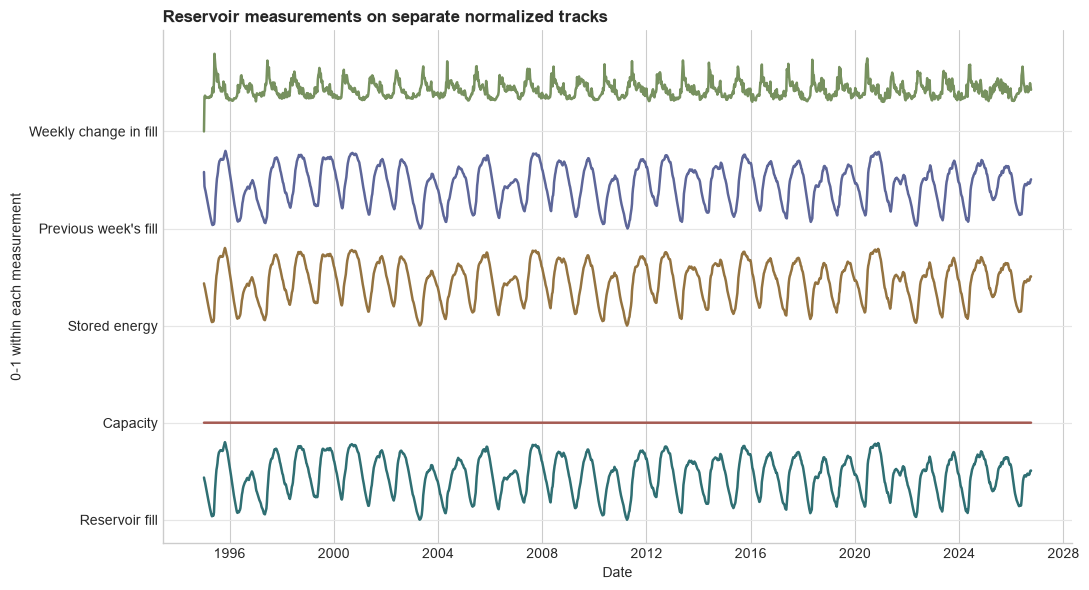

In [5]:
# The measurements use different units, so I scale each one to its own
# historical 0-1 range before placing them in the same figure.
fig, ax = plt.subplots(figsize=(11, 6))
track_gap = 1.25

for track, ((column, (label, _, _)), color) in enumerate(
    zip(MEASUREMENTS.items(), COLORS)
):
    values = national[column]
    spread = values.max() - values.min()
    scaled = (values - values.min()) / spread if spread else pd.Series(0.0, index=values.index)
    baseline = track * track_gap
    ax.axhline(baseline, color="#E7E7E7", linewidth=0.7)
    ax.plot(national["date"], scaled + baseline, color=color, linewidth=1.8)

ax.set_yticks(
    [track * track_gap for track in range(len(MEASUREMENTS))],
    [label for label, _, _ in MEASUREMENTS.values()],
)
ax.set_title("Reservoir measurements on separate normalized tracks", loc="left", fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("0-1 within each measurement")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Testing Cassandra and Spark

Cassandra runs in the local Docker container named my_cassandra. I use the Python driver to create the table, then start Spark with the same connector version used in the course material.

In [6]:
from cassandra.cluster import Cluster

# A short connection test confirms that the local container is reachable.
cluster = Cluster(["127.0.0.1"], port=9042, connect_timeout=10)
cassandra_session = cluster.connect()
print("Connected to Cassandra:", cassandra_session.cluster.metadata.cluster_name)

cassandra_session.execute(
    """
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}
    """
)
cassandra_session.execute(
    """
    CREATE TABLE IF NOT EXISTS ind320.cross_border_flows (
        connection text,
        year int,
        direction text,
        timestamp timestamp,
        month int,
        value_mw double,
        transfer_mwh double,
        PRIMARY KEY ((connection, year), direction, timestamp)
    ) WITH CLUSTERING ORDER BY (direction ASC, timestamp ASC)
    """
)
print("The ind320.cross_border_flows table is ready.")

Connected to Cassandra: Test Cluster
The ind320.cross_border_flows table is ready.


In [7]:
import os
import subprocess
import sys

# Spark's workers need the same Python version as this notebook kernel.
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

# Spark 3.5 did not run with Java 24 on my Mac, so I ask macOS for Java 17 here.
# This keeps the setup inside the notebook instead of changing the whole computer.
java_home = subprocess.run(
    ["/usr/libexec/java_home", "-v", "17"],
    check=True,
    capture_output=True,
    text=True,
).stdout.strip()
os.environ["JAVA_HOME"] = java_home

from pyspark.sql import SparkSession

# I use the same connector version as the course notebook so the Spark and
# Scala versions match instead of leaving that choice to the computer.
spark = (
    SparkSession.builder
    .appName("IND320Project2")
    .config("spark.sql.session.timeZone", "UTC")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1",
    )
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .config(
        "spark.sql.extensions",
        "com.datastax.spark.connector.CassandraSparkExtensions",
    )
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

# I read the table created in the cell above before adding the API rows.
# Seeing its schema here confirms that Spark is actually using the connector.
cassandra_test = spark.read.format("org.apache.spark.sql.cassandra").options(
    table="cross_border_flows", keyspace="ind320"
).load()
cassandra_test.printSchema()
cassandra_test.limit(1).show(truncate=False)


/Users/sivanhadji/IND320/.venv/lib/python3.12/site-packages/pyspark/bin/load-spark-env.sh: line 68: /bin/ps: Operation not permitted


:: loading settings :: url = jar:file:/Users/sivanhadji/IND320/.venv/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /Users/sivanhadji/.ivy2/cache
The jars for the packages stored in: /Users/sivanhadji/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-ff253319-f9cc-4868-86f9-66a7f25aa304;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-s

:: resolution report :: resolve 193ms :: artifacts dl 6ms
	:: modules in use:
	com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 from central in [default]
	com.datastax.oss#native-protocol;1.5.1 from central in [default]
	com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 from central in [default]
	com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 from central in [default]
	com.thoughtworks.paranamer#paranamer;2.8 from central in [default]
	com.typesafe#config;1.4.1 from central in [default]
	io.dropwizard.metrics#metrics-core;4.1.18 from central in [default]
	org.apache.cassandra#java-driver-core-shaded;4.18.1 from central in [default]
	org.apache.cassandra#java-driver-mapper-runtime;4.18.1 from central in [default]
	org.apache.cassandra#java-driver-query-builder;4.18.1 from central in [default]
	org.apache.commons#commons-lang3;3.10 from central in [default]
	org.hdrhistogram#HdrHistogram;2.1.12 from central in [default]
	org.reactivestreams#reactive-st

root
 |-- connection: string (nullable = false)
 |-- year: integer (nullable = false)
 |-- direction: string (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- month: integer (nullable = true)
 |-- transfer_mwh: double (nullable = true)
 |-- value_mw: double (nullable = true)



+----------+----+-----------+-------------------+-----+------------+--------+
|connection|year|direction  |timestamp          |month|transfer_mwh|value_mw|
+----------+----+-----------+-------------------+-----+------------+--------+
|NO3-SE2   |2025|Into Norway|2024-12-31 23:00:00|1    |527.5975    |527.5975|
+----------+----+-----------+-------------------+-----+------------+--------+



## Downloading the last two complete years from ENTSO-E

The token is read from the private local settings, never printed or written in this notebook. I use the last two complete calendar years, 2024 and 2025 for this hand-in. I request each border in both directions and keep Norwegian calendar years while storing timestamps in UTC.

These are physical flows, not electricity production. ENTSO-E reports average power in MW. For a complete hour, multiplying the hourly mean by one hour gives energy in MWh. I use MW in the line plots and summed MWh in the yearly pie. Source: [ENTSO-E physical flows](https://transparencyplatform.zendesk.com/hc/en-us/articles/16583889683476-Physical-Flows-12-1-G).

In [8]:
from entsoe import EntsoeRawClient
from entsoe_utils import fetch_norwegian_transfers

api_key = os.environ.get("ENTSOE_API_KEY")
if not api_key:
    raise ValueError(
        "Set ENTSOE_API_KEY in the local environment before running this section."
    )

current_year = pd.Timestamp.now(tz="Europe/Oslo").year
start = pd.Timestamp(f"{current_year - 2}-01-01", tz="Europe/Oslo")
end = pd.Timestamp(f"{current_year}-01-01", tz="Europe/Oslo")

# The helper converts the API's XML response into a table and caches each year.
client = EntsoeRawClient(api_key=api_key, timeout=60, retry_count=1)
transfers = fetch_norwegian_transfers(client, start, end)
print(f"Downloaded {len(transfers):,} hourly rows from {start.date()} to {end.date()}.")
display(transfers.head())

# I check coverage before treating the sums as yearly totals.
coverage = transfers.groupby(["connection", "direction", "year"])["value_mw"].count().rename("recorded_hours").reset_index()
coverage["expected_hours"] = coverage["year"].map(
    lambda year: len(pd.date_range(f"{year}-01-01", f"{year + 1}-01-01",
                                   freq="h", tz="Europe/Oslo", inclusive="left"))
)
coverage["missing_hours"] = coverage["expected_hours"] - coverage["recorded_hours"]
assert not transfers.duplicated(["connection", "direction", "timestamp"]).any()
assert transfers["value_mw"].dropna().ge(0).all()
display(coverage)

Checked NO1-SE3, Out of Norway.


Checked NO1-SE3, Into Norway.


Checked NO2-DK1, Out of Norway.


Checked NO2-DK1, Into Norway.


Checked NO2-NL, Out of Norway.


...

Checked NO4-FI, Out of Norway.


Checked NO4-FI, Into Norway.


Downloaded 315,792 hourly rows from 2024-01-01 to 2026-01-01.


,timestamp,value_mw,connection,direction,transfer_mwh,year,month
17544,2023-12-31 23:00:00+00:00,1655.6900,NO1-SE3,Into Norway,1655.6900,2024,1
0,2023-12-31 23:00:00+00:00,0.0000,NO1-SE3,Out of Norway,0.0000,2024,1
122808,2023-12-31 23:00:00+00:00,1399.0425,NO2-DE-LU,Into Norway,1399.0425,2024,1
105264,2023-12-31 23:00:00+00:00,0.0000,NO2-DE-LU,Out of Norway,0.0000,2024,1
52632,2023-12-31 23:00:00+00:00,1637.5200,NO2-DK1,Into Norway,1637.5200,2024,1


,connection,direction,year,recorded_hours,expected_hours,missing_hours
0,NO1-SE3,Into Norway,2024,8784,8784,0
1,NO1-SE3,Into Norway,2025,8760,8760,0
2,NO1-SE3,Out of Norway,2024,8784,8784,0
3,NO1-SE3,Out of Norway,2025,8760,8760,0
4,NO2-DE-LU,Into Norway,2024,8784,8784,0
5,NO2-DE-LU,Into Norway,2025,8760,8760,0
6,NO2-DE-LU,Out of Norway,2024,8784,8784,0
7,NO2-DE-LU,Out of Norway,2025,8760,8760,0
8,NO2-DK1,Into Norway,2024,8784,8784,0
9,NO2-DK1,Into Norway,2025,8760,8760,0


## Storing the API rows in Cassandra with Spark

In [9]:
# I pass timezone-aware Python datetimes so Spark keeps the same instant.
# An explicit schema also avoids differences between pandas and Spark versions.
spark_input = [
    (row.timestamp.to_pydatetime(), row.connection, row.direction,
     float(row.value_mw), float(row.transfer_mwh), int(row.year), int(row.month))
    for row in transfers.itertuples(index=False)
]

spark_transfers = spark.createDataFrame(
    spark_input,
    "timestamp timestamp, connection string, direction string, "
    "value_mw double, transfer_mwh double, year int, month int",
)
(
    spark_transfers.write
    .format("org.apache.spark.sql.cassandra")
    .mode("append")
    .options(table="cross_border_flows", keyspace="ind320")
    .save()
)
print("The ENTSO-E rows were written to local Cassandra.")

The ENTSO-E rows were written to local Cassandra.


## Extracting the columns needed later

I read the table back through Spark instead of continuing with the original Pandas object. This makes the Cassandra-to-Spark step visible and keeps only the columns needed for plots and MongoDB.

In [10]:
from pyspark.sql import functions as F

raw_spark = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(table="cross_border_flows", keyspace="ind320")
    .load()
)

curated_spark = (
    raw_spark
    .select(
        "timestamp", "connection", "direction", "value_mw",
        "transfer_mwh", "year", "month"
    )
    .filter(F.col("year").isin([current_year - 2, current_year - 1]))
    .dropDuplicates(["connection", "direction", "timestamp"])
    .orderBy("timestamp", "connection", "direction")
)
curated_spark.show(8, truncate=False)
# collect() keeps this compatible with the local pandas 3 installation.
# Epoch seconds avoid a second conversion through the Mac's local timezone.
export_rows = curated_spark.withColumn("timestamp", F.col("timestamp").cast("long"))
curated = pd.DataFrame([row.asDict() for row in export_rows.collect()])
curated["timestamp"] = pd.to_datetime(curated["timestamp"], unit="s", utc=True)

+-------------------+----------+-------------+---------+------------+----+-----+
|timestamp          |connection|direction    |value_mw |transfer_mwh|year|month|
+-------------------+----------+-------------+---------+------------+----+-----+
|2023-12-31 23:00:00|NO1-SE3   |Into Norway  |1655.69  |1655.69     |2024|1    |
|2023-12-31 23:00:00|NO1-SE3   |Out of Norway|0.0      |0.0         |2024|1    |
|2023-12-31 23:00:00|NO2-DE-LU |Into Norway  |1399.0425|1399.0425   |2024|1    |
|2023-12-31 23:00:00|NO2-DE-LU |Out of Norway|0.0      |0.0         |2024|1    |
|2023-12-31 23:00:00|NO2-DK1   |Into Norway  |1637.52  |1637.52     |2024|1    |
|2023-12-31 23:00:00|NO2-DK1   |Out of Norway|0.0      |0.0         |2024|1    |
|2023-12-31 23:00:00|NO2-GB    |Into Norway  |0.0      |0.0         |2024|1    |
|2023-12-31 23:00:00|NO2-GB    |Out of Norway|463.78   |463.78      |2024|1    |
+-------------------+----------+-------------+---------+------------+----+-----+
only showing top 8 rows



## Making the yearly direction plot

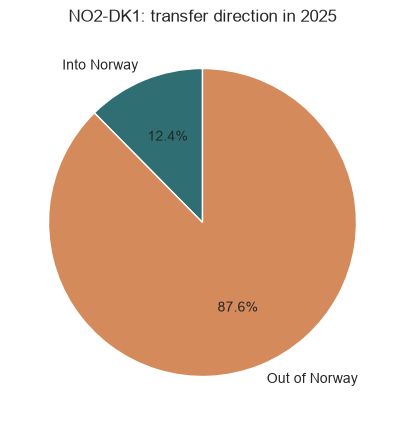

In [11]:
# I use one connection and the latest complete year as a clear example.
chosen_connection = "NO2-DK1"
chosen_year = current_year - 1

annual = curated.loc[
    (curated["connection"] == chosen_connection)
    & (curated["year"] == chosen_year)
]
direction_totals = annual.groupby("direction")["transfer_mwh"].sum()

fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(
    direction_totals,
    labels=direction_totals.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#2F6F73", "#D58A5C"],
    wedgeprops={"linewidth": 1, "edgecolor": "white"},
)
ax.set_title(f"{chosen_connection}: transfer direction in {chosen_year}")
plt.show()

## Making the first-month line plot

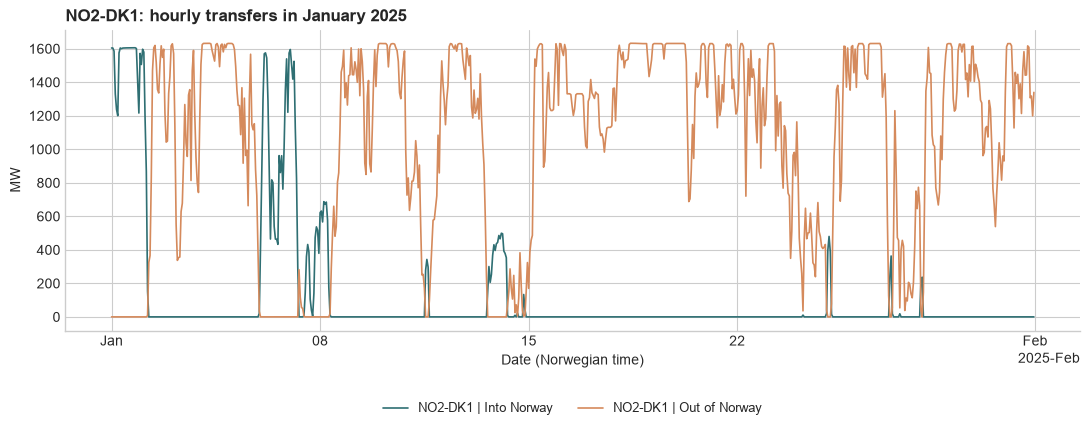

In [12]:
from zoneinfo import ZoneInfo

# I keep the same connection as the pie chart and show January.
# Two separate lines make imports and exports easier to compare.
first_month = 1
first_month_rows = curated.loc[
    (curated["year"] == chosen_year) & (curated["month"] == first_month)
    & (curated["connection"] == chosen_connection)
].copy()

fig, ax = plt.subplots(figsize=(11, 4.5))
for (connection, direction), rows in first_month_rows.groupby(
    ["connection", "direction"]
):
    ax.plot(
        rows["timestamp"], rows["value_mw"],
        label=f"{connection} | {direction}", linewidth=1.2,
        color="#2F6F73" if direction == "Into Norway" else "#D58A5C",
    )

ax.set_title(f"{chosen_connection}: hourly transfers in January {chosen_year}", loc="left", fontweight="bold")
ax.set_xlabel("Date (Norwegian time)")
ax.set_ylabel("MW")
ax.spines[["top", "right"]].set_visible(False)
locator = mdates.AutoDateLocator(minticks=4, maxticks=7, tz=ZoneInfo("Europe/Oslo"))
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=ZoneInfo("Europe/Oslo")))
ax.legend(ncols=2, frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.tight_layout()
plt.show()

## Writing the curated rows to MongoDB

The MongoDB address is read from the private local settings. I insert new hours together and only update rows whose values have changed. The unique index prevents the same connection, direction and timestamp from being stored twice.

In [13]:
from pymongo import MongoClient, ReplaceOne

mongo_uri = os.environ.get("MONGODB_URI")
if not mongo_uri:
    raise ValueError(
        "Set MONGODB_URI in the local environment before running this section."
    )

mongo_client = MongoClient(mongo_uri, serverSelectionTimeoutMS=20000, tz_aware=True)
collection = mongo_client["ind320"]["power_transfers"]
collection.create_index(
    [("connection", 1), ("direction", 1), ("timestamp", 1)],
    unique=True,
)

# Each timestamp is converted to a Python datetime before sending it to MongoDB.
mongo_rows = curated.to_dict("records")
# I compare existing rows first, so rerunning does not rewrite unchanged hours.
existing = {
    (row["connection"], row["direction"], row["timestamp"]): row
    for row in collection.find({}, {"_id": 0})
}
new_rows = []
changes = []
for row in mongo_rows:
    row["timestamp"] = row["timestamp"].to_pydatetime()
    key = {
        "connection": row["connection"],
        "direction": row["direction"],
        "timestamp": row["timestamp"],
    }
    previous = existing.get((row["connection"], row["direction"], row["timestamp"]))
    if previous is None:
        new_rows.append(row)
    elif previous != row:
        changes.append(ReplaceOne(key, row))

# Batching new documents is much quicker than one upsert per hour.
for start_row in range(0, len(new_rows), 5000):
    collection.insert_many(new_rows[start_row:start_row + 5000], ordered=False)
for start_row in range(0, len(changes), 1000):
    collection.bulk_write(changes[start_row:start_row + 1000], ordered=False)

print(f"Added {len(new_rows):,} new rows and changed {len(changes):,} existing rows.")
print(f"MongoDB now contains {collection.count_documents({}):,} transfer rows.")

Added 229,792 new rows and changed 0 existing rows.


MongoDB now contains 315,792 transfer rows.


## AI use

I used ChatGPT and Codex as learning support when I needed help understanding some of the Spark, Cassandra and MongoDB functions. They also helped me check the project structure and explain how the different components connect. I reviewed the suggestions, rewrote parts of the code and made my own changes. Codex also helped with the practical setup in VS Code and will help publish the finished branch to GitHub and Streamlit, which saves time on those steps.

## Work log

I continued Part 2 in the same repository and kept the changes on project-part-2. The first version stays on main while I work on the new data sources. This makes it easier to see how the project develops without replacing the version from the first hand-in.

I replaced reservoirs.csv with NVE's Magasinstatistikk API and reused the English column names from Part 1. After sorting the dates, I recreated the plots and reorganised the reservoir pages after the assignment update on 12 October. Radio buttons now select EL, NO or VASS for both the line plot and the small table graphs. NVE's area catalogue helped me explain the boundaries and showed that VASS 4 has no measurement series. The endpoint has no date parameters, so the interval slider keeps the selected months from the full API response.

After ENTSO-E approved my account, I downloaded physical flows for nine Norwegian cross-border connections in both directions. I chose 2024 and 2025 as the last two complete calendar years. Some monthly requests timed out, so I used yearly requests and saved each result locally. The finished dataset contains 315,792 hourly rows, with every expected hour present. I store timestamps in UTC but use Norwegian time for months and years. This keeps the first hour of January in the correct year.

Spark writes the rows to Cassandra and reads back the columns used for the plots. The local setup needed Java 17 and matching Python versions for the notebook and Spark workers. I then sent the extracted rows to MongoDB. Inserting new rows in batches was faster than upserting every hour, and unchanged rows are left alone when I rerun the notebook.

The Streamlit transfer page reads MongoDB directly. I tested all nine connection choices and both years. After the updated instructions, the right column uses pills to select any set of months for the connection chosen on the left. The yearly pie uses energy in MWh, while the direction lines show power in MW. I kept one connection in the notebook's January plot so the two directions are readable. Comparing the database results with the original download confirmed that all rows matched.

All notebook cells have been run and the figures checked. I pushed the work to the project-part-2 branch and deployed the same branch to my existing Streamlit address. After adding the MongoDB connection through Streamlit Secrets and checking the Atlas network access, I tested the published NVE pages and the transfer page. The credentials stay out of GitHub. The PDF and screencast remain for the hand-in.